In [1]:
#Importing libraries
from scipy import stats
import geopandas as gpd
from stargazer.stargazer import Stargazer
import statsmodels.formula.api as smf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from dateutil.relativedelta import relativedelta
import datetime
import os
import statsmodels.api as sm
from datetime import datetime

In [2]:
#Loading all CSV files from a folder into a dictionary of DataFrames
def load_dataframes_from_csv_folder(folder_path):
    dataframes = {}
    for filename in os.listdir(folder_path):
        if filename.endswith(".csv"):
            file_path = os.path.join(folder_path, filename)
            df = pd.read_csv(file_path)
            df['source_file'] = filename
            dataframes[filename] = df
    return dataframes


folder_path = r'/Users/aditisurve/Desktop/Empowerment_data'
dataframes_dict = load_dataframes_from_csv_folder(folder_path)

# Concatenate all DataFrames into one big DataFrame
big_dataframe = pd.concat(dataframes_dict.values(), ignore_index=True)


big_dataframe = big_dataframe[big_dataframe['experiment_one.1.player.Cows_vacc'] != np.nan]


column_name = 'experiment_one.1.player.Cows_vacc'
big_dataframe = big_dataframe.dropna(subset=[column_name])

col_names = big_dataframe.columns

In [3]:
# Extract day and date from source_file
big_dataframe['day_of_week'] = big_dataframe['source_file'].str.extract(r'([a-zA-Z]+)Data')
big_dataframe['date'] = big_dataframe['source_file'].str.extract(r'(\d{2}:\d{2}:\d{4}|\d{2}April|\d{2}:\d{2}:\d{4})')

big_dataframe['date'] = np.where(big_dataframe['source_file'] =='week1data_11_to_15_march.csv', '11:03:2024', big_dataframe['date'])
big_dataframe['date'] = np.where(big_dataframe['source_file'] =='thursdayData6:6:2024.csv', '6:06:2024', big_dataframe['date'])
big_dataframe['date'] = np.where(big_dataframe['source_file'] =='mondayData1:07:2024.csv', '1:07:2024', big_dataframe['date'])
big_dataframe['date'] = np.where(big_dataframe['source_file'] =='mondayData3:06:2024.csv', '3:06:2024', big_dataframe['date'])
big_dataframe['date'] = np.where(big_dataframe['source_file'] == 'wednesday6:03:2024.csv', '6:03:2024', big_dataframe['date'])
big_dataframe['date'] = np.where(big_dataframe['source_file'] =='fridayData8:03:2024.csv', '8:03:2024', big_dataframe['date'])
big_dataframe['date'] = np.where(big_dataframe['source_file'] == 'johnMorningData-1.csv', '7:03:2024', big_dataframe['date'])
big_dataframe['date'] = np.where(big_dataframe['source_file'] == 'johnFieldData-1.csv', '7:03:2024', big_dataframe['date'])
big_dataframe['date'] = np.where(big_dataframe['source_file'] =='tuesdayData23April.csv', '23:04:2024', big_dataframe['date'])
big_dataframe['date'] = np.where(big_dataframe['source_file'] =='wednesdayData24April.csv', '24:04:2024', big_dataframe['date'])
big_dataframe['date'] = np.where(big_dataframe['source_file'] =='thursdayData7:03:2024.csv', '7:03:2024', big_dataframe['date'])
big_dataframe['date'] = np.where(big_dataframe['source_file'] =='thursdayData25April.csv', '25:04:2024', big_dataframe['date'])

big_dataframe['date'] = pd.to_datetime(big_dataframe['date'], format='%d:%m:%Y')



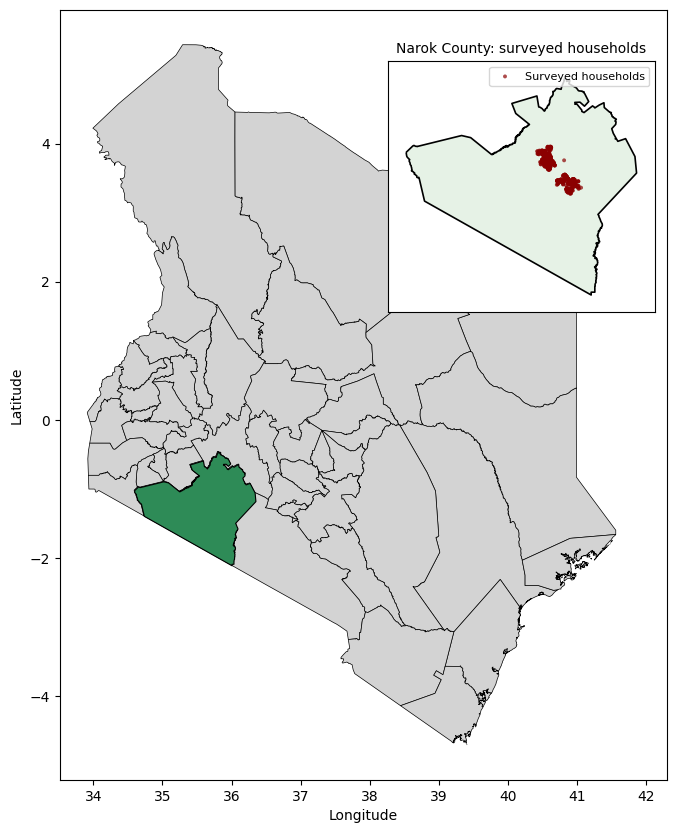

In [30]:

# Figure 1: Map of Kenya highlighting Narok county
# 1. Load Kenya county boundaries
kenya_shapefile_path = (
    "/Users/aditisurve/Downloads/kenyan-counties/County.shp"
)

kenya_gdf = gpd.read_file(kenya_shapefile_path).to_crs("EPSG:4326")

narok_gdf = kenya_gdf[
    kenya_gdf["COUNTY"].str.strip().str.casefold() == "narok"
].copy()

if narok_gdf.empty:
    raise ValueError("Narok County was not found in the shapefile.")

# 2. Load household data — update this path if needed
household_data_path = (
    "/Users/aditisurve/Desktop/AHIL/AHIL_baseline_data_household.csv"
)

households = pd.read_csv(household_data_path)

# Column 's' contains: latitude longitude altitude accuracy
coords = households["s"].astype("string").str.split(expand=True)

households["latitude"] = pd.to_numeric(coords[0], errors="coerce")
households["longitude"] = pd.to_numeric(coords[1], errors="coerce")

# Keep observations with valid latitude and longitude
valid = (
    households["latitude"].between(-90, 90)
    & households["longitude"].between(-180, 180)
)
households = households.loc[valid].copy()

if households.empty:
    raise ValueError("No valid household coordinates were found.")

household_gdf = gpd.GeoDataFrame(
    households,
    geometry=gpd.points_from_xy(
        households["longitude"],
        households["latitude"]
    ),
    crs="EPSG:4326"
)

# 3. Main map: Kenya highlighting Narok County
fig, ax = plt.subplots(figsize=(10, 10))

kenya_gdf.plot(
    ax=ax,
    color="lightgrey",
    edgecolor="black",
    linewidth=0.5
)

narok_gdf.plot(
    ax=ax,
    color="seagreen",
    edgecolor="black",
    linewidth=0.8
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")

# 4. Inset: full Narok County outline and household locations
inset_ax = ax.inset_axes([0.54, 0.57, 0.44, 0.40])
inset_ax.set_facecolor("white")

# County background
narok_gdf.plot(
    ax=inset_ax,
    color="#e6f2e6",
    edgecolor="none"
)

# Household locations
household_gdf.plot(
    ax=inset_ax,
    color="darkred",
    markersize=8,
    alpha=0.7,
    edgecolor="none",
    label="Surveyed households"
)

# County outline drawn last to keep it visible
narok_gdf.boundary.plot(
    ax=inset_ax,
    color="black",
    linewidth=1.2
)

# Display the entire county rather than zooming to the households
xmin, ymin, xmax, ymax = narok_gdf.total_bounds

xpad = (xmax - xmin) * 0.08
ypad = (ymax - ymin) * 0.08

inset_ax.set_xlim(xmin - xpad, xmax + xpad)
inset_ax.set_ylim(ymin - ypad, ymax + ypad)
inset_ax.set_aspect("equal")

inset_ax.set_title(
    "Narok County: surveyed households",
    fontsize=10
)
inset_ax.set_xticks([])
inset_ax.set_yticks([])
inset_ax.legend(
    loc="best",
    fontsize=8,
    frameon=True
)

# 5. Save and display
fig.savefig(
    "Kenya_Narok_households.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    "Kenya_Narok_households.pdf",
    bbox_inches="tight"
)

plt.show()

In [5]:
#cleaning the data for analysis


df_2 = pd.read_csv(
    r'//Users/aditisurve/Desktop/Empowerment_data/pilot_full.csv')
df_2.columns = df_2.iloc[0]
df_2 = df_2[1:]

df_2.rename(columns={
            'empowerment_app.6.player.household_id': 'participant.household_id'}, inplace=True)

big_dataframe = pd.concat([big_dataframe, df_2], axis=0)


# calculate age
df_1 = pd.read_csv(r'//Users/aditisurve/Desktop/AHIL/ahil_enrollment.csv')


def calculate_age(birthdate):
    birthdate = datetime.strptime(birthdate, "%Y-%m-%d")
    today = datetime.today()
    age = today.year - birthdate.year - \
        ((today.month, today.day) < (birthdate.month, birthdate.day))
    return age


df_1['Age'] = df_1['hh_DOB']
df_1['Age'] = df_1['Age'].apply(lambda x: calculate_age(x))
df_age = df_1[['householdID', 'Age']]


# for strata fixed effects
df_2 = pd.read_csv('/Users/aditisurve/Desktop/stratified_revised.csv')
df_strata = df_2[['quartile_gndr', 'household_id']]


df_age_strata = pd.merge(df_age, df_strata, how='left',
                         left_on='householdID', right_on='household_id')
df_age_strata = df_age_strata.drop(columns=['householdID'])

df_age_strata = df_age_strata.rename(
    columns={'household_id': 'participant.household_id'})

df_age_strata = df_age_strata.dropna(subset=['participant.household_id'])


big_dataframe['carry_payoffs.1.player.ecf_aware'] = np.where(
    big_dataframe['carry_payoffs.1.player.ecf_aware'] == 2, '0', '1')
big_dataframe['carry_payoffs.1.player.ecf_case'] = np.where(
    big_dataframe['carry_payoffs.1.player.ecf_case'] == 2, '0', '1')
big_dataframe['carry_payoffs.1.player.vaccine_aware'] = np.where(
    big_dataframe['carry_payoffs.1.player.vaccine_aware'] == 2, '0', '1')
big_dataframe['carry_payoffs.1.player.vaccinated'] = np.where(
    big_dataframe['carry_payoffs.1.player.vaccinated'] == 2, '0', '1')


game_one = big_dataframe[['experiment_one.1.player.treatment_A', 'experiment_one.1.player.treatment_B', 'experiment_one.1.player.treatment_C',
                          'experiment_one.1.player.Cows_vacc', 'experiment_one.6.player.payoff', 'experiment_one.1.player.rp', 'carry_payoffs.1.player.ruminant_solely',
                          'carry_payoffs.1.player.choice01', 'carry_payoffs.1.player.choice02', 'carry_payoffs.1.player.choice03', 'carry_payoffs.1.player.choice04',
                          'carry_payoffs.1.player.choice05', 'carry_payoffs.1.player.choice06', 'carry_payoffs.1.player.education', 'participant.household_id', 'date',
                          'experiment_one.1.player.acaricide', 'carry_payoffs.1.player.ecf_aware', 'carry_payoffs.1.player.ecf_case', 'carry_payoffs.1.player.vaccine_aware',
                          'carry_payoffs.1.player.vaccinated', 'carry_payoffs.1.player.ruminant_total', 'experiment_one.5.player.payoff', 'experiment_one.4.player.payoff',
                          'experiment_one.2.player.payoff', 'experiment_one.1.player.payoff', 
                          'experiment_one.1.player.animal_lost', 'experiment_one.2.player.animal_lost',
                          'experiment_one.3.player.animal_lost', 'experiment_one.4.player.animal_lost',
                          'experiment_one.5.player.animal_lost', 'experiment_one.6.player.animal_lost',
                          'experiment_one.1.player.question_1', 'experiment_one.1.player.question_2',
                          'experiment_one.1.player.question_3', 'experiment_one.1.player.question_4',
                          'experiment_one.1.player.question_5']]


merged_gameone = pd.merge(df_age_strata, game_one,
                          on='participant.household_id', how='right')


column_name = 'participant.household_id'

merged_gameone = merged_gameone.dropna(subset=[column_name])

dummy_edu = pd.get_dummies(
    merged_gameone['carry_payoffs.1.player.education'], prefix='Education_')

merged_gameone = pd.concat([merged_gameone, dummy_edu], axis=1)

dummy_qtrgen = pd.get_dummies(
    merged_gameone['quartile_gndr'], prefix='Strata_')

merged_gameone = pd.concat([merged_gameone, dummy_qtrgen], axis=1)


selected_columns = ['carry_payoffs.1.player.choice01', 'carry_payoffs.1.player.choice02', 'carry_payoffs.1.player.choice03', 'carry_payoffs.1.player.choice04',
                    'carry_payoffs.1.player.choice05', 'carry_payoffs.1.player.choice06']

# Replace 0 with 1 in selected columns
merged_gameone.loc[:, selected_columns] = merged_gameone.loc[:,
                                                             selected_columns].replace(0, 1)
merged_gameone.fillna(0, inplace=True)

merged_gameone['ownership_score'] = merged_gameone[['carry_payoffs.1.player.choice01', 'carry_payoffs.1.player.choice02', 'carry_payoffs.1.player.choice03', 'carry_payoffs.1.player.choice04',
                                                    'carry_payoffs.1.player.choice05', 'carry_payoffs.1.player.choice06']].sum(axis=1)


game_two = big_dataframe[['empowerment_app.1.player.treat_A', 'empowerment_app.1.player.treat_B', 'empowerment_app.1.player.treat_C',
                          'empowerment_app.6.player.payoff', 'empowerment_app.1.player.Cows_vacc', 'empowerment_app.1.player.rp', 'carry_payoffs.1.player.ruminant_solely',
                          'carry_payoffs.1.player.choice01', 'carry_payoffs.1.player.choice02', 'carry_payoffs.1.player.choice03', 'carry_payoffs.1.player.choice04',
                          'carry_payoffs.1.player.choice05', 'carry_payoffs.1.player.choice06', 'carry_payoffs.1.player.education', 'participant.household_id', 'date',
                          'experiment_one.1.player.acaricide', 'carry_payoffs.1.player.ecf_aware', 'carry_payoffs.1.player.ecf_case', 'carry_payoffs.1.player.vaccine_aware',
                          'carry_payoffs.1.player.vaccinated', 'empowerment_app.5.player.payoff', 'empowerment_app.4.player.payoff', 'empowerment_app.3.player.payoff',
                          'empowerment_app.2.player.payoff', 'empowerment_app.1.player.payoff']]


game_two.rename(columns={'empowerment_app.1.player.treat_A': 'experiment_one.1.player.treatment_A',
                         'empowerment_app.1.player.treat_B': 'experiment_one.1.player.treatment_B',
                         'empowerment_app.1.player.treat_C': 'experiment_one.1.player.treatment_C',
                         'empowerment_app.6.player.payoff': 'experiment_one.6.player.payoff',
                         'empowerment_app.1.player.Cows_vacc': 'experiment_one.1.player.Cows_vacc',
                         'empowerment_app.1.player.rp': 'experiment_one.1.player.rp',
                         
                         }, inplace=True)


merged_gametwo = pd.merge(df_age_strata, game_two,
                          on='participant.household_id', how='right')


column_name = 'participant.household_id'
merged_gametwo = merged_gametwo.dropna(subset=[column_name])



dummy_edu = pd.get_dummies(
    merged_gametwo['carry_payoffs.1.player.education'], prefix='Education_')

merged_gametwo = pd.concat([merged_gametwo, dummy_edu], axis=1)

dummy_qtrgen = pd.get_dummies(
    merged_gametwo['quartile_gndr'], prefix='Strata_')

merged_gametwo = pd.concat([merged_gametwo, dummy_qtrgen], axis=1)


selected_columns = ['carry_payoffs.1.player.choice01', 'carry_payoffs.1.player.choice02', 'carry_payoffs.1.player.choice03', 'carry_payoffs.1.player.choice04',
                    'carry_payoffs.1.player.choice05', 'carry_payoffs.1.player.choice06']

# Replace 0 with 1 in selected columns
merged_gametwo.loc[:, selected_columns] = merged_gametwo.loc[:,
                                                             selected_columns].replace(0, 1)
merged_gametwo.fillna(0, inplace=True)

merged_gametwo['ownership_score'] = merged_gametwo[['carry_payoffs.1.player.choice01', 'carry_payoffs.1.player.choice02', 'carry_payoffs.1.player.choice03', 'carry_payoffs.1.player.choice04',
                                                    'carry_payoffs.1.player.choice05', 'carry_payoffs.1.player.choice06']].sum(axis=1)


game_pooled = pd.concat([merged_gameone, merged_gametwo], axis=0)


col_names = merged_gameone.columns


merged_gameone.rename(columns={'experiment_one.1.player.treatment_A': 'treatment_A',
                               'experiment_one.1.player.treatment_B': 'treatment_B',
                               'experiment_one.1.player.treatment_C': 'treatment_C',
                               'experiment_one.6.player.payoff': 'payoff',
                               'experiment_one.5.player.payoff': 'payoff_5',
                               'experiment_one.4.player.payoff': 'payoff_4',
                               'experiment_one.3.player.payoff': 'payoff_3',
                               'experiment_one.2.player.payoff': 'payoff_2',
                               'experiment_one.1.player.payoff': 'payoff_1',
                               'experiment_one.1.player.Cows_vacc': 'Cows_vacc',
                               'experiment_one.1.player.rp': 'rp',
                               'carry_payoffs.1.player.ruminant_solely': 'solely',
                               'experiment_one.1.player.acaricide': 'acaricide',
                               'Education__1.0': 'Education_1',
                               'Education__2.0': 'Education_2',
                               'Education__3.0': 'Education_3',
                               'Education__4.0': 'Education_4',
                               'Education__5.0': 'Education_5',
                               'Education__6.0': 'Education_6',
                               'Education__8.0': 'Education_8',
                               'Education__9.0': 'Education_9',
                               'carry_payoffs.1.player.ecf_aware': 'ecf_aware',
                               'carry_payoffs.1.player.ecf_case': 'ecf_case',
                               'carry_payoffs.1.player.vaccine_aware': 'vaccine_aware',
                               'carry_payoffs.1.player.vaccinated': 'vaccinated',

                               }, inplace=True)

merged_gametwo.rename(columns={'experiment_one.1.player.treatment_A': 'treatment_A',
                               'experiment_one.1.player.treatment_B': 'treatment_B',
                               'experiment_one.1.player.treatment_C': 'treatment_C',
                               'experiment_one.6.player.payoff': 'payoff',
                               'experiment_one.5.player.payoff': 'payoff_5',
                               'experiment_one.4.player.payoff': 'payoff_4',
                               'experiment_one.3.player.payoff': 'payoff_3',
                               'experiment_one.2.player.payoff': 'payoff_2',
                               'experiment_one.1.player.payoff': 'payoff_1',
                               'experiment_one.1.player.Cows_vacc': 'Cows_vacc',
                               'experiment_one.1.player.rp': 'rp',
                               'carry_payoffs.1.player.ruminant_solely': 'solely',
                               'experiment_one.1.player.acaricide': 'acaricide',
                               'Education__1.0': 'Education_1',
                               'Education__2.0': 'Education_2',
                               'Education__3.0': 'Education_3',
                               'Education__4.0': 'Education_4',
                               'Education__5.0': 'Education_5',
                               'Education__6.0': 'Education_6',
                               'Education__8.0': 'Education_8',
                               'Education__9.0': 'Education_9',
                               'carry_payoffs.1.player.ecf_aware': 'ecf_aware',
                               'carry_payoffs.1.player.ecf_case': 'ecf_case',
                               'carry_payoffs.1.player.vaccine_aware': 'vaccine_aware',
                               'carry_payoffs.1.player.vaccinated': 'vaccinated',

                               }, inplace=True)

game_pooled.rename(columns={'experiment_one.1.player.treatment_A': 'treatment_A',
                            'experiment_one.1.player.treatment_B': 'treatment_B',
                            'experiment_one.1.player.treatment_C': 'treatment_C',
                            'experiment_one.6.player.payoff': 'payoff',
                            'experiment_one.5.player.payoff': 'payoff_5',
                            'experiment_one.4.player.payoff': 'payoff_4',
                            'experiment_one.3.player.payoff': 'payoff_3',
                            'experiment_one.2.player.payoff': 'payoff_2',
                            'experiment_one.1.player.payoff': 'payoff_1',
                            'experiment_one.1.player.Cows_vacc': 'Cows_vacc',
                            'experiment_one.1.player.rp': 'rp',
                            'carry_payoffs.1.player.ruminant_solely': 'solely',
                            'experiment_one.1.player.acaricide': 'acaricide',
                            'Education__1.0': 'Education_1',
                            'Education__2.0': 'Education_2',
                            'Education__3.0': 'Education_3',
                            'Education__4.0': 'Education_4',
                            'Education__5.0': 'Education_5',
                            'Education__6.0': 'Education_6',
                            'Education__8.0': 'Education_8',
                            'Education__9.0': 'Education_9',
                            'carry_payoffs.1.player.ecf_aware': 'ecf_aware',
                            'carry_payoffs.1.player.ecf_case': 'ecf_case',
                            'carry_payoffs.1.player.vaccine_aware': 'vaccine_aware',
                            'carry_payoffs.1.player.vaccinated': 'vaccinated',
                            }, inplace=True)


merged_gameone['Cows_nvacc'] = 10 - merged_gameone['Cows_vacc']
merged_gametwo['Cows_nvacc'] = 10 - merged_gametwo['Cows_vacc']
game_pooled['Cows_nvacc'] = 10 - game_pooled['Cows_vacc']

#replace zero age with mean age for merged_gameone, merged_gametwo and game_pooled
mean_age = merged_gameone['Age'].replace(0, np.nan).mean()
merged_gameone['Age'] = merged_gameone['Age'].replace(0, mean_age)  
mean_age = merged_gametwo['Age'].replace(0, np.nan).mean()
merged_gametwo['Age'] = merged_gametwo['Age'].replace(0, mean_age)  
mean_age = game_pooled['Age'].replace(0, np.nan).mean()
game_pooled['Age'] = game_pooled['Age'].replace(0, mean_age)        




/var/folders/gj/fpgd_72j79b4gb7wcq4bl0_40000gn/T/ipykernel_85081/779274823.py:12: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  big_dataframe = pd.concat([big_dataframe, df_2], axis=0)
/var/folders/gj/fpgd_72j79b4gb7wcq4bl0_40000gn/T/ipykernel_85081/779274823.py:96: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  selected_columns].replace(0, 1)
/var/folders/gj/fpgd_72j79b4gb7wcq4bl0_40000gn/T/ipykernel_85081/779274823.py:97: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and

In [ ]:
# Table 1: Baseline respondent characteristics
labels = {
    'Age': 'Age',
    'Education_1': 'Education: None',
    'Education_2': 'Education: Pre-school',
    'Education_3': 'Education: Primary',
    'Education_4': 'Education: Primary(not complete)',
    'Education_5': 'Education: Secondary',
    'Education_6': 'Education: Secondary(not complete)',
    'Education_8': 'Education: Tertiary',
    'Education_9': 'Education: Tertiary(not complete)',
    'carry_payoffs.1.player.ruminant_total':
        'Cattle owned in total by household',
    'solely': 'Cattle owned solely',
    'carry_payoffs.1.player.choice01': 'Right to give cattle as gift',
    'carry_payoffs.1.player.choice02': 'Right to sell cattle',
    'carry_payoffs.1.player.choice03': 'Right to loan cattle',
    'carry_payoffs.1.player.choice04': 'Right to pledge cattle as collateral',
    'carry_payoffs.1.player.choice05': 'Right to slaughter cattle'
}

sum_stat = (
    merged_gameone[list(labels)]
    .apply(pd.to_numeric, errors='raise')
    .astype(float)
    .rename(columns=labels)
    .describe()
    .T[['count', 'mean', 'std', 'min', '50%']]
    .rename(columns={
        'count': 'Count',
        'mean': 'Mean/Proportion',
        'std': 'Std',
        'min': 'Min',
        '50%': 'Med'
    })
    .round(2)
)

display(sum_stat)

,Count,Mean/Proportion,Std,Min,Med
Age,602.0,43.14,13.21,23.0,41.0
Education: None,602.0,0.55,0.50,0.0,1.0
Education: Pre-school,602.0,0.02,0.16,0.0,0.0
Education: Primary,602.0,0.09,0.29,0.0,0.0
Education: Primary(not complete),602.0,0.15,0.36,0.0,0.0
Education: Secondary,602.0,0.07,0.26,0.0,0.0
Education: Secondary(not complete),602.0,0.06,0.24,0.0,0.0
Education: Tertiary,602.0,0.03,0.17,0.0,0.0
Education: Tertiary(not complete),602.0,0.01,0.10,0.0,0.0
Cattle owned in total by household,602.0,17.44,22.87,0.0,10.0


In [ ]:
#Table 2: Outcome variables summary statistics

outcomes = {
    'Calves vaccinated in Game One': merged_gameone['Cows_vacc'],
    'Calves vaccinated in Game Two': merged_gametwo['Cows_vacc'],
    'Final points in Game One': merged_gameone['payoff'],
    'Final points in Game Two': merged_gametwo['payoff']
}

outcome_summary = pd.DataFrame({
    label: pd.to_numeric(values, errors='raise').astype(float)
           .describe()[['mean', 'std', 'min', 'max']]
    for label, values in outcomes.items()
}).T.rename(columns={
    'mean': 'Mean',
    'std': 'Std',
    'min': 'Min',
    'max': 'Max'
}).round(2)

display(outcome_summary)

,Mean,Std,Min,Max
Calves vaccinated in Game One,9.17,1.81,1.0,10.0
Calves vaccinated in Game Two,9.10,1.95,0.0,10.0
Final points in Game One,1808.06,471.38,-44.0,2867.0
Final points in Game Two,1746.13,473.37,-255.0,2690.0


In [10]:
# Create dummy variables for controls
merged_gameone['acaricide'] = np.where(merged_gameone['acaricide'] == 0, '9.0', merged_gameone['acaricide'])
merged_gametwo['acaricide'] = np.where(merged_gametwo['acaricide'] == 0, '9.0', merged_gametwo['acaricide'])
game_pooled['acaricide'] = np.where(game_pooled['acaricide'] == 0, '9.0', game_pooled['acaricide'])

merged_gameone['acaricide_low'] = np.where(merged_gameone['acaricide'] == '6.0', 1, 0)
merged_gametwo['acaricide_low'] = np.where(merged_gametwo['acaricide'] == '6.0', 1, 0)
game_pooled['acaricide_low'] = np.where(game_pooled['acaricide'] == '6.0', 1, 0)

merged_gameone['nudge'] = (merged_gameone['date'] > '2024-06-06').astype(int)
merged_gametwo['nudge'] = (merged_gametwo['date'] > '2024-06-06').astype(int)
game_pooled['nudge'] = (game_pooled['date'] > '2024-06-06').astype(int)

merged_gameone['edu_none'] = np.where(merged_gameone['Education_1'] == 1, 1, 0)
merged_gametwo['edu_none'] = np.where(merged_gametwo['Education_1'] == 1, 1, 0)
game_pooled['edu_none'] = np.where(game_pooled['Education_1'] == 1, 1, 0)

merged_gameone['pre_school'] = np.where((merged_gameone['Education_2'] == 1) | (merged_gameone['Education_4'] == 1), 1, 0)
merged_gametwo['pre_school'] = np.where(
    (merged_gametwo['Education_2'] == 1) | (merged_gametwo['Education_4'] == 1), 1, 0)
game_pooled['pre_school'] = np.where(
    (game_pooled['Education_2'] == 1) | (game_pooled['Education_4'] == 1), 1, 0)

merged_gameone['primary'] = np.where((merged_gameone['Education_3'] == 1) | (merged_gameone['Education_6'] == 1), 1, 0)
merged_gametwo['primary'] = np.where((merged_gametwo['Education_3'] == 1) | (merged_gametwo['Education_6'] == 1), 1, 0)
game_pooled['primary'] = np.where((game_pooled['Education_3'] == 1) | (game_pooled['Education_6'] == 1), 1, 0)

merged_gameone['secondary'] = np.where((merged_gameone['Education_5'] == 1), 1, 0)
merged_gametwo['secondary'] = np.where((merged_gametwo['Education_5'] == 1), 1, 0)
game_pooled['secondary'] = np.where((game_pooled['Education_5'] == 1), 1, 0)

merged_gameone['tertiary'] = np.where((merged_gameone['Education_8'] == 1), 1, 0)
merged_gametwo['tertiary'] = np.where((merged_gametwo['Education_8'] == 1), 1, 0)
game_pooled['tertiary'] = np.where((game_pooled['Education_8'] == 1), 1, 0)

merged_gameone['tertiary_notcompleted'] = np.where((merged_gameone['Education_9'] == 1), 1, 0)
merged_gametwo['tertiary_notcompleted'] = np.where((merged_gametwo['Education_9'] == 1), 1, 0)
game_pooled['tertiary_notcompleted'] = np.where((game_pooled['Education_9'] == 1), 1, 0)

# Labels for regression results
regression_labels = {
    'Intercept': 'Constant',
    'const': 'Constant',
    'treatment_A': 'Ownership and Income',
    'treatment_B': 'Income Only',
    'treatment_C': 'Ownership Only',
    'ownership_score': 'Real rights index',
    'solely': 'Real cows owned',
    'rp': 'Risk of ECF',
    'med_risk': 'Medium risk',
    'high_risk': 'High risk',
    'low_risk': 'Low risk',
    'Age': 'Age',
    'acaricide_low': 'Low acaricide cost',
    'nudge': 'Nudge',
    'pre_school': 'Pre-school',
    'primary': 'Primary',
    'secondary': 'Secondary',
    'tertiary': 'Tertiary',
    'tertiary_notcompleted': 'Tertiary(not complete)'
}

outcome_labels = {
    'Cows_vacc': 'Vaccine decision',
    'payoff': 'Final points',
    'normalized_payoff': 'Normalized Points'
}


def paper_summary(model, table=None):
    labels = regression_labels.copy()

    # Tables 6 and 7 use these compact treatment labels
    if table in [6, 7]:
        labels['treatment_A'] = 'Ownership&Income'
        labels['treatment_C'] = 'OwnershipOnly'

    def rename_term(term):
        if ':' in term:
            interaction_labels = {
                **labels,
                'ownership_score': 'Real rights',
                'rp': 'Risk'
            }
            return ' × '.join(
                interaction_labels.get(part, part)
                for part in term.split(':')
            )

        return labels.get(term, term)

    variable_names = [
        rename_term(name) for name in model.model.exog_names
    ]

    outcome = outcome_labels.get(
        model.model.endog_names, model.model.endog_names
    )

    print(model.summary(xname=variable_names, yname=outcome))

In [ ]:
# Table 3: Impact of empowerment on vaccine decisions and final points.

# Game 1: Vaccine decision
model11 = smf.ols(
    formula='Cows_vacc ~ 1 + treatment_C + treatment_A + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=merged_gameone
).fit(cov_type='HC3')

paper_summary(model11, 6)


# Game 2: Vaccine decision
model12 = smf.ols(
    formula='Cows_vacc ~ 1 + treatment_C + treatment_A + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=merged_gametwo
).fit(cov_type='HC3')

paper_summary(model12, 6)


# Game 1: Final points
model21 = smf.ols(
    formula='payoff ~ 1 + treatment_C + treatment_A + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=merged_gameone
).fit(cov_type='HC3')

paper_summary(model21, 6)


# Game 2: Final points
model22 = smf.ols(
    formula='payoff ~ 1 + treatment_C + treatment_A + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=merged_gametwo
).fit(cov_type='HC3')

paper_summary(model22, 6)

                            OLS Regression Results                            
Dep. Variable:       Vaccine decision   R-squared:                       0.059
Model:                            OLS   Adj. R-squared:                  0.030
Method:                 Least Squares   F-statistic:                     3.492
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           1.70e-06
Time:                        16:42:27   Log-Likelihood:                -1191.5
No. Observations:                 602   AIC:                             2421.
Df Residuals:                     583   BIC:                             2505.
Df Model:                          18                                         
Covariance Type:                  HC3                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Constant                  

In [ ]:
#Table 4: Impact of empowerment on Normalized Points.
# Normalization of payoffs

#ownership and income

merged_gameone['normalized_payoff'] = np.where((merged_gameone['acaricide_low'] == 1) & (
    merged_gameone['treatment_A'] == 1), merged_gameone['payoff']/4170, 0)
merged_gametwo['normalized_payoff'] = np.where((merged_gametwo['acaricide_low'] == 1) & (
    merged_gametwo['treatment_A'] == 1), merged_gametwo['payoff']/4170, 0)
game_pooled['normalized_payoff'] = np.where((game_pooled['acaricide_low'] == 1) & (
    game_pooled['treatment_A'] == 1), game_pooled['payoff']/4170, 0)


merged_gameone['normalized_payoff'] = np.where((merged_gameone['acaricide_low'] == 0) & (
    merged_gameone['treatment_A'] == 1), merged_gameone['payoff']/4250, merged_gameone['normalized_payoff'])
merged_gametwo['normalized_payoff'] = np.where((merged_gametwo['acaricide_low'] == 0) & (
    merged_gametwo['treatment_A'] == 1), merged_gametwo['payoff']/4250, merged_gametwo['normalized_payoff'])
game_pooled['normalized_payoff'] = np.where((game_pooled['acaricide_low'] == 0) & (
    game_pooled['treatment_A'] == 1), game_pooled['payoff']/4250, game_pooled['normalized_payoff'])


# ownership only

merged_gameone['normalized_payoff'] = np.where((merged_gameone['acaricide_low'] == 1) & (
    merged_gameone['treatment_C'] == 1), merged_gameone['payoff']/1930, merged_gameone['normalized_payoff'])
merged_gametwo['normalized_payoff'] = np.where((merged_gametwo['acaricide_low'] == 1) & (
    merged_gametwo['treatment_C'] == 1), merged_gametwo['payoff']/1930, merged_gametwo['normalized_payoff'])
game_pooled['normalized_payoff'] = np.where((game_pooled['acaricide_low'] == 1) & (
    game_pooled['treatment_C'] == 1), game_pooled['payoff']/1930, game_pooled['normalized_payoff'])


merged_gameone['normalized_payoff'] = np.where((merged_gameone['acaricide_low'] == 0) & (
    merged_gameone['treatment_C'] == 1), merged_gameone['payoff']/2050, merged_gameone['normalized_payoff'])
merged_gametwo['normalized_payoff'] = np.where((merged_gametwo['acaricide_low'] == 0) & (
    merged_gametwo['treatment_C'] == 1), merged_gametwo['payoff']/2050, merged_gametwo['normalized_payoff'])
game_pooled['normalized_payoff'] = np.where((game_pooled['acaricide_low'] == 0) & (
    game_pooled['treatment_C'] == 1), game_pooled['payoff']/2050, game_pooled['normalized_payoff'])

# income only

merged_gameone['normalized_payoff'] = np.where((merged_gameone['acaricide_low'] == 1) & (
    merged_gameone['treatment_B'] == 1), merged_gameone['payoff']/1980, merged_gameone['normalized_payoff'])
merged_gametwo['normalized_payoff'] = np.where((merged_gametwo['acaricide_low'] == 1) & (
    merged_gametwo['treatment_B'] == 1), merged_gametwo['payoff']/1980, merged_gametwo['normalized_payoff'])
game_pooled['normalized_payoff'] = np.where((game_pooled['acaricide_low'] == 1) & (
    game_pooled['treatment_B'] == 1), game_pooled['payoff']/1980, game_pooled['normalized_payoff'])


merged_gameone['normalized_payoff'] = np.where((merged_gameone['acaricide_low'] == 0) & (
    merged_gameone['treatment_B'] == 1), merged_gameone['payoff']/2040, merged_gameone['normalized_payoff'])
merged_gametwo['normalized_payoff'] = np.where((merged_gametwo['acaricide_low'] == 0) & (
    merged_gametwo['treatment_B'] == 1), merged_gametwo['payoff']/2040, merged_gametwo['normalized_payoff'])
game_pooled['normalized_payoff'] = np.where((game_pooled['acaricide_low'] == 0) & (
    game_pooled['treatment_B'] == 1), game_pooled['payoff']/2040, game_pooled['normalized_payoff'])

# Regressions: Table 7
X_cols = [
    'treatment_C', 'treatment_A', 'Age', 'acaricide_low', 'nudge',
    'Strata__first1', 'Strata__first2', 'Strata__fourth1', 'Strata__fourth2',
    'Strata__second1', 'Strata__second2', 'Strata__third1',
    'rp', 'pre_school', 'primary', 'secondary',
    'tertiary', 'tertiary_notcompleted'
]

# Game 1: Normalized Points
X = merged_gameone[X_cols].apply(pd.to_numeric, errors='coerce')
y = pd.to_numeric(
    merged_gameone['normalized_payoff'], errors='coerce'
)

X = sm.add_constant(X)
mask = X.notna().all(axis=1) & y.notna()

X_clean = X.loc[mask].astype(float)
y_clean = y.loc[mask].astype(float)
y_clean.name = 'normalized_payoff'

model_norm1 = sm.OLS(y_clean, X_clean).fit(cov_type='HC3')

paper_summary(model_norm1, 7)


# Game 2: Normalized Points
X = merged_gametwo[X_cols].apply(pd.to_numeric, errors='coerce')
y = pd.to_numeric(
    merged_gametwo['normalized_payoff'], errors='coerce'
)

X = sm.add_constant(X)
mask = X.notna().all(axis=1) & y.notna()

X_clean = X.loc[mask].astype(float)
y_clean = y.loc[mask].astype(float)
y_clean.name = 'normalized_payoff'

model_norm2 = sm.OLS(y_clean, X_clean).fit(cov_type='HC3')

paper_summary(model_norm2, 7)

                            OLS Regression Results                            
Dep. Variable:      Normalized Points   R-squared:                       0.605
Model:                            OLS   Adj. R-squared:                  0.592
Method:                 Least Squares   F-statistic:                     96.44
Date:                Sun, 18 Oct 2026   Prob (F-statistic):          2.38e-161
Time:                        16:46:37   Log-Likelihood:                 325.16
No. Observations:                 602   AIC:                            -612.3
Df Residuals:                     583   BIC:                            -528.7
Df Model:                          18                                         
Covariance Type:                  HC3                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Constant                   0

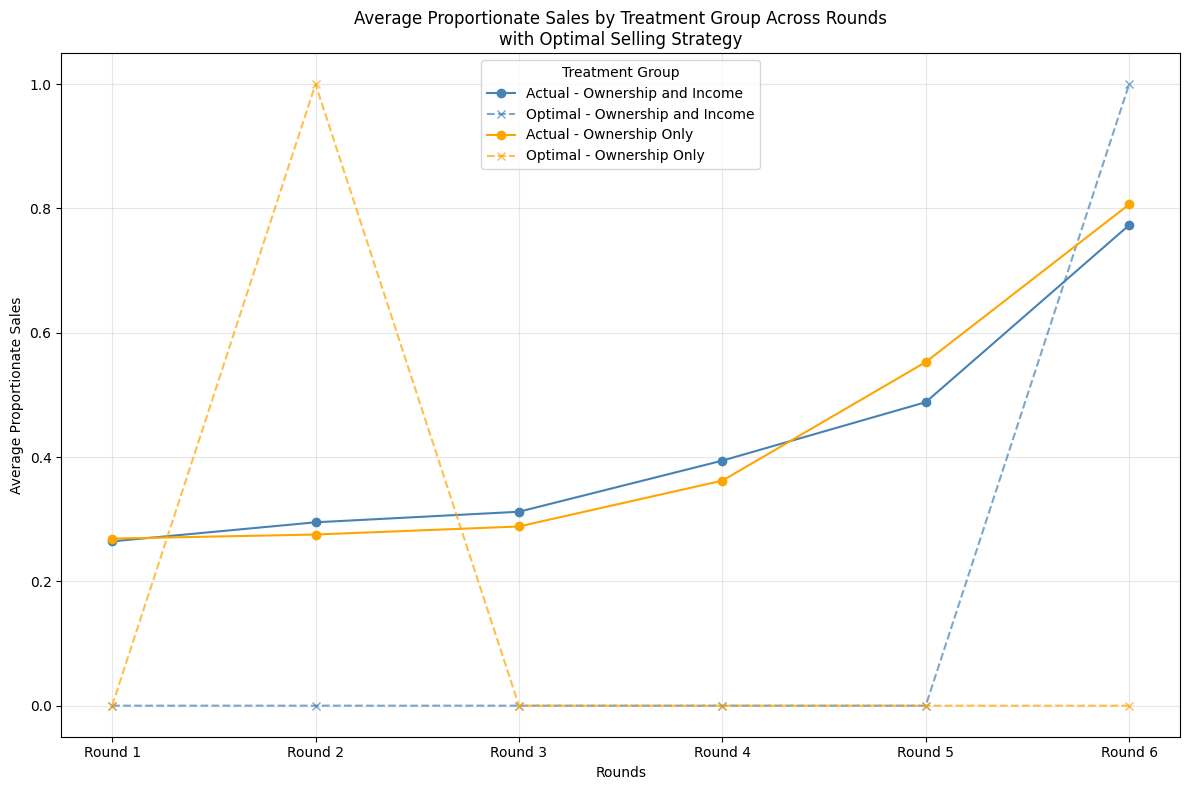

In [ ]:
#Figure 5: Average proportionate sales
# Convert sales, losses, and treatment indicators to numeric
numeric_columns = [
    f'empowerment_app.{r}.player.{variable}'
    for r in range(1, 7)
    for variable in ['Cows_sold_vacc', 'Cows_sold_nvacc', 'animal_lost']
] + [
    f'empowerment_app.1.player.treat_{treatment}'
    for treatment in ['A', 'B', 'C']
]

big_dataframe[numeric_columns] = (
    big_dataframe[numeric_columns]
    .replace(r'^\s*$', np.nan, regex=True)
    .apply(pd.to_numeric, errors='raise')
)
# Prepare Game 2 data
prefix = 'empowerment_app'
round_names = ['one', 'two', 'three', 'four', 'five', 'six']

sale_game_two = pd.DataFrame(index=big_dataframe.index)

sale_game_two['treatment'] = np.select(
    [
        big_dataframe[f'{prefix}.1.player.treat_C'].eq(1),
        big_dataframe[f'{prefix}.1.player.treat_B'].eq(1),
        big_dataframe[f'{prefix}.1.player.treat_A'].eq(1),
    ],
    ['C', 'B', 'A'],
    default='0'
)

previous_sales = pd.Series(0.0, index=big_dataframe.index)
previous_losses = pd.Series(0.0, index=big_dataframe.index)

for r, name in enumerate(round_names, start=1):
    sales = (
        big_dataframe[f'{prefix}.{r}.player.Cows_sold_vacc']
        + big_dataframe[f'{prefix}.{r}.player.Cows_sold_nvacc']
    )
    losses = big_dataframe[f'{prefix}.{r}.player.animal_lost']

    remaining = 10 - previous_sales - previous_losses

    sale_game_two[f'proportion_{name}'] = (
        (sales - losses) / remaining.replace(0, np.nan)
    )

    previous_sales = previous_sales + sales
    previous_losses = previous_losses + losses

sale_game_two = sale_game_two.loc[
    sale_game_two['treatment'].isin(['A', 'C'])
].copy()

# Average proportions by treatment
proportion_columns = [f'proportion_{name}' for name in round_names]

prop_sales_by_treatment = (
    sale_game_two.groupby('treatment')[proportion_columns].mean().T
)

# Plot actual sales and supplied optimal benchmarks
treatment_labels = {
    'A': 'Ownership and Income',
    'C': 'Ownership Only'
}
colors = {'A': 'steelblue', 'C': 'orange'}
optimal = {
    'A': [0, 0, 0, 0, 0, 1],
    'C': [0, 1, 0, 0, 0, 0]
}

rounds = np.arange(1, 7)
fig, ax = plt.subplots(figsize=(12, 8))

for treatment in prop_sales_by_treatment.columns:
    label = treatment_labels[treatment]

    ax.plot(
        rounds, prop_sales_by_treatment[treatment],
        marker='o', color=colors[treatment],
        label=f'Actual - {label}'
    )
    ax.plot(
        rounds, optimal[treatment],
        linestyle='--', marker='x', color=colors[treatment],
        linewidth=1.5, alpha=0.7,
        label=f'Optimal - {label}'
    )

ax.set(
    xticks=rounds,
    xticklabels=[f'Round {r}' for r in rounds],
    xlabel='Rounds',
    ylabel='Average Proportionate Sales',
    title='Average Proportionate Sales by Treatment Group Across Rounds\n'
          'with Optimal Selling Strategy'
)
ax.legend(title='Treatment Group')
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

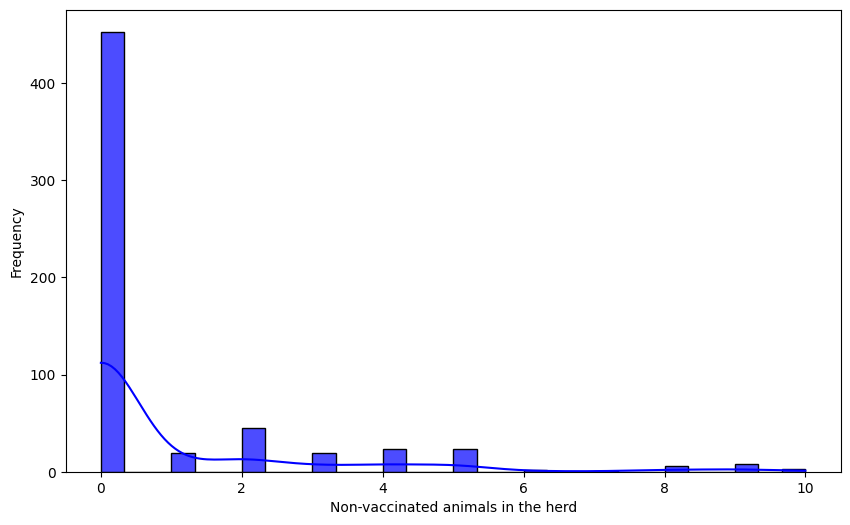

In [14]:
#Figure 7: Distribution of the number of non-vaccinated cows in the herd
# Generate 1000 random values from a normal distribution
data = merged_gametwo['Cows_nvacc']

# Create the histogram with KDE using Seaborn
plt.figure(figsize=(10, 6))
sns.histplot(data, bins=30, kde=True, color='blue',
             edgecolor='black', alpha=0.7)

# Adding labels and title
plt.xlabel('Non-vaccinated animals in the herd')
plt.ylabel('Frequency')
plt.title('')

# Display the plot
plt.show()

In [ ]:
#Table 5: Zero-Inflated Negative Binomial Results
# ZINB results: Game One, Game Two, and pooled

import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.discrete.count_model import ZeroInflatedNegativeBinomialP

# Same explanatory variables as Table 6
controls = [
    'treatment_A', 'treatment_C',
    'Age', 'acaricide_low', 'nudge', 'rp',
    'pre_school', 'primary', 'secondary',
    'tertiary', 'tertiary_notcompleted',
    'Strata__first1', 'Strata__first2',
    'Strata__fourth1', 'Strata__fourth2',
    'Strata__second1', 'Strata__second2', 'Strata__third1'
]

labels = {
    'const': 'Intercept',
    'treatment_A': 'Ownership and Income',
    'treatment_C': 'Ownership Only',
    'Age': 'Age (decades)',
    'acaricide_low': 'Low acaricide cost',
    'nudge': 'Nudge',
    'rp': 'Risk of ECF',
    'pre_school': 'Pre-school',
    'primary': 'Primary',
    'secondary': 'Secondary',
    'tertiary': 'Tertiary',
    'tertiary_notcompleted': 'Tertiary(not complete)'
}

zinb_results = {}

for game, data in [
    ('Game One', merged_gameone),
    ('Game Two', merged_gametwo),
    ('Pooled', game_pooled)
]:
    print(f'\n{"=" * 60}\n{game}\n{"=" * 60}')

    # Prepare numeric data
    clean = (
        data[['Cows_vacc'] + controls]
        .apply(pd.to_numeric, errors='raise')
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .astype(float)
    )

    y = (10 - clean['Cows_vacc']).rename('Unvaccinated cows')

    if not (y.between(0, 10) & y.eq(y.round())).all():
        raise ValueError(
            f'{game}: unvaccinated cows must be integers from 0 to 10.'
        )

    X = sm.add_constant(clean[controls], has_constant='add')

    # Rescale age for numerical stability
    X['Age'] = X['Age'] / 10

    # Same explanatory variables in both components
    Z = X.copy()

    if np.linalg.matrix_rank(X.to_numpy()) < X.shape[1]:
        raise ValueError(
            f'{game}: explanatory variables contain exact collinearity.'
        )

    model = ZeroInflatedNegativeBinomialP(
        endog=y,
        exog=X,
        exog_infl=Z,
        inflation='logit',
        p=2
    )

    # Positive dispersion constraint
    n_parameters = Z.shape[1] + X.shape[1] + 1
    bounds = [(None, None)] * (n_parameters - 1) + [(1e-8, None)]

    successful_fits = []

    # Try alternative starting values
    for zero_probability in [0.2, 0.5, 0.75]:
        start = np.zeros(n_parameters)

        start[Z.columns.get_loc('const')] = np.log(
            zero_probability / (1 - zero_probability)
        )

        start[Z.shape[1] + X.columns.get_loc('const')] = np.log(
            max(y.mean() / (1 - zero_probability), 0.01)
        )

        start[-1] = 0.1

        try:
            candidate = model.fit(
                start_params=start,
                method='lbfgs',
                bounds=bounds,
                maxiter=3000,
                cov_type='HC0',
                disp=False
            )

            valid = (
                candidate.mle_retvals.get('converged', False)
                and np.isfinite(candidate.llf)
                and np.isfinite(candidate.params).all()
                and np.isfinite(candidate.bse).all()
                and (candidate.bse > 0).all()
                and candidate.params['alpha'] > 1e-6
            )

            if valid:
                successful_fits.append(candidate)
            else:
                print(
                    f'Start {zero_probability}: '
                    f'converged={candidate.mle_retvals.get("converged", False)}, '
                    f'alpha={candidate.params["alpha"]:.6g}; '
                    'fit did not pass validation.'
                )

        except (ValueError, np.linalg.LinAlgError) as error:
            print(f'Start {zero_probability}: {error}')

    if not successful_fits:
        print(
            'No validated interior ZINB fit found for this sample. '
            'Do not report coefficients from the failed attempts.'
        )
        continue

    # Keep the validated fit with the highest log-likelihood
    result = max(successful_fits, key=lambda fit: fit.llf)
    zinb_results[game] = result

    print('Converged:', result.mle_retvals['converged'])
    print('Observations:', int(result.nobs))
    print('Dispersion alpha:', round(result.params['alpha'], 6))

    # Readable labels for both components
    parameter_names = []

    for name in result.params.index:
        if name.startswith('inflate_'):
            original = name.removeprefix('inflate_')
            parameter_names.append(
                'Logit: ' + labels.get(original, original)
            )
        elif name == 'alpha':
            parameter_names.append('Dispersion alpha')
        else:
            parameter_names.append(
                'Count: ' + labels.get(name, name)
            )

    print(
        result.summary(
            xname=parameter_names,
            yname='Unvaccinated cows'
        )
    )


Game One


/Users/aditisurve/Practice/.venv/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:3937: RuntimeWarning: invalid value encountered in log
  a1 * np.log(a1) + y * np.log(mu) -
/Users/aditisurve/Practice/.venv/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:3938: RuntimeWarning: invalid value encountered in log
  (y + a1) * np.log(a2))
/Users/aditisurve/Practice/.venv/lib/python3.14/site-packages/statsmodels/base/model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '


Start 0.2: converged=True, alpha=1.37606e-05; fit did not pass validation.


/Users/aditisurve/Practice/.venv/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:4329: RuntimeWarning: overflow encountered in exp
  return np.exp(linpred)
/Users/aditisurve/Practice/.venv/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:3937: RuntimeWarning: invalid value encountered in multiply
  a1 * np.log(a1) + y * np.log(mu) -
/Users/aditisurve/Practice/.venv/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:3974: RuntimeWarning: divide by zero encountered in log
  dgterm = dgpart + np.log(a1 / a2) + 1 - a3 / a2
/Users/aditisurve/Practice/.venv/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:3977: RuntimeWarning: invalid value encountered in multiply
  dparams = (a4 * dgterm -
/Users/aditisurve/Practice/.venv/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:3980: RuntimeWarning: invalid value encountered in multiply
  dparams = (self.exog.T * mu * dparams).T
/Users/aditisurve/Practice/

Start 0.5: converged=False, alpha=1.4011e-08; fit did not pass validation.


/Users/aditisurve/Practice/.venv/lib/python3.14/site-packages/statsmodels/base/model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '
/Users/aditisurve/Practice/.venv/lib/python3.14/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Start 0.75: converged=False, alpha=1e-08; fit did not pass validation.
No validated interior ZINB fit found for this sample. Do not report coefficients from the failed attempts.

Game Two
Converged: True
Observations: 602
Dispersion alpha: 0.091999
                     ZeroInflatedNegativeBinomialP Regression Results                    
Dep. Variable:                 Unvaccinated cows   No. Observations:                  602
Model:             ZeroInflatedNegativeBinomialP   Df Residuals:                      583
Method:                                      MLE   Df Model:                           18
Date:                           Sun, 18 Oct 2026   Pseudo R-squ.:                 0.05791
Time:                                   16:47:22   Log-Likelihood:                -608.57
converged:                                  True   LL-Null:                       -645.97
Covariance Type:                             HC0   LLR p-value:                 6.811e-09
                               

/Users/aditisurve/Practice/.venv/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:3937: RuntimeWarning: invalid value encountered in log
  a1 * np.log(a1) + y * np.log(mu) -
/Users/aditisurve/Practice/.venv/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:3938: RuntimeWarning: invalid value encountered in log
  (y + a1) * np.log(a2))


Converged: True
Observations: 1204
Dispersion alpha: 0.047538
                     ZeroInflatedNegativeBinomialP Regression Results                    
Dep. Variable:                 Unvaccinated cows   No. Observations:                 1204
Model:             ZeroInflatedNegativeBinomialP   Df Residuals:                     1185
Method:                                      MLE   Df Model:                           18
Date:                           Sun, 18 Oct 2026   Pseudo R-squ.:                 0.03005
Time:                                   16:47:25   Log-Likelihood:                -1187.9
converged:                                  True   LL-Null:                       -1224.7
Covariance Type:                             HC0   LLR p-value:                 1.102e-08
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Logit: Intercept      

/Users/aditisurve/Practice/.venv/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:3937: RuntimeWarning: invalid value encountered in log
  a1 * np.log(a1) + y * np.log(mu) -
/Users/aditisurve/Practice/.venv/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:3938: RuntimeWarning: invalid value encountered in log
  (y + a1) * np.log(a2))


In [ ]:
# Table 6: HTE: Cattle owned at baseline and ownership rights.

# Game 1: Vaccine decision
model31 = smf.ols(
    formula='Cows_vacc ~ 1 + ownership_score * solely + treatment_C * ownership_score + treatment_A * ownership_score + treatment_C * solely + treatment_A * solely + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=merged_gameone
).fit(cov_type='HC3')

paper_summary(model31, 9)


# Game 2: Vaccine decision
model32 = smf.ols(
    formula='Cows_vacc ~ 1 + treatment_C * ownership_score + treatment_A * ownership_score + treatment_C * solely + treatment_A * solely + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=merged_gametwo
).fit(cov_type='HC3')

paper_summary(model32, 9)


# Game 1: Final points
model41 = smf.ols(
    formula='payoff ~ 1 + treatment_C * ownership_score + treatment_A * ownership_score + treatment_C * solely + treatment_A * solely + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=merged_gameone
).fit(cov_type='HC3')

paper_summary(model41, 9)


# Game 2: Final points
model42 = smf.ols(
    formula='payoff ~ 1 + treatment_C * ownership_score + treatment_A * ownership_score + treatment_C * solely + treatment_A * solely + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=merged_gametwo
).fit(cov_type='HC3')

paper_summary(model42, 9)


                            OLS Regression Results                            
Dep. Variable:       Vaccine decision   R-squared:                       0.085
Model:                            OLS   Adj. R-squared:                  0.046
Method:                 Least Squares   F-statistic:                     2.488
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           9.72e-05
Time:                        16:47:37   Log-Likelihood:                -1182.9
No. Observations:                 602   AIC:                             2418.
Df Residuals:                     576   BIC:                             2532.
Df Model:                          25                                         
Covariance Type:                  HC3                                         
                                             coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------

In [ ]:
# Table 7: HTE: Risk of infection in the game

# Game 1: Vaccine decision
model51 = smf.ols(
    formula='Cows_vacc ~ 1 + treatment_C * rp + treatment_A * rp + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=merged_gameone
).fit(cov_type='HC3')

paper_summary(model51, 10)


# Game 2: Vaccine decision
model52 = smf.ols(
    formula='Cows_vacc ~ 1 + treatment_C * rp + treatment_A * rp + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=merged_gametwo
).fit(cov_type='HC3')

paper_summary(model52, 10)


# Game 1: Final points
model61 = smf.ols(
    formula='payoff ~ 1 + treatment_C * rp + treatment_A * rp + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=merged_gameone
).fit(cov_type='HC3')

paper_summary(model61, 10)


# Game 2: Final points
model62 = smf.ols(
    formula='payoff ~ 1 + treatment_C * rp + treatment_A * rp + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=merged_gametwo
).fit(cov_type='HC3')

paper_summary(model62, 10)


                            OLS Regression Results                            
Dep. Variable:       Vaccine decision   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.030
Method:                 Least Squares   F-statistic:                     2.932
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           2.26e-05
Time:                        16:48:02   Log-Likelihood:                -1190.4
No. Observations:                 602   AIC:                             2423.
Df Residuals:                     581   BIC:                             2515.
Df Model:                          20                                         
Covariance Type:                  HC3                                         
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Constant          

In [ ]:
# Table A.3.1: Comprehension Checks summary statistics

labels = {
    'experiment_one.1.player.friend_days': 'Visit days',
    'experiment_one.1.player.friend_weeks': 'Visit weeks',
    'experiment_one.1.player.ecf_nooutbreak': 'ECF no outbreak',
    'experiment_one.1.player.ecf_outbreak': 'ECF outbreak'
}

check = (
    big_dataframe[list(labels)]
    .apply(pd.to_numeric, errors='raise')
    .astype(float)
    .rename(columns=labels)
)

# Calculate checks using the numeric variables
check['Visit check'] = (
    (check['Visit days'] <= check['Visit weeks'])
    .astype(float)
    .where(check[['Visit days', 'Visit weeks']].notna().all(axis=1))
)

check['ECF outbreak check'] = (
    (check['ECF no outbreak'] >= check['ECF outbreak'])
    .astype(float)
    .where(check[['ECF no outbreak', 'ECF outbreak']].notna().all(axis=1))
)

check_summary = (
    check.describe()
    .T[[ 'mean', 'std', 'min', 'max']]
    .rename(columns={
        'mean': 'Mean/Proportion',
        'std': 'Std',
        'min': 'Min',
        'max': 'Max'
    })
    .round(2)
)

display(check_summary)

In [ ]:
# Supplementary Online Appendix

# Table A.4.1: OLS results pooled across both games.

# Pooled: Vaccine decision
model1p = smf.ols(
    formula='Cows_vacc ~ 1 + treatment_C + treatment_A + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=game_pooled
).fit(cov_type='HC3')

paper_summary(model1p, 6)


# Pooled: Final points
model2p = smf.ols(
    formula='payoff ~ 1 + treatment_C + treatment_A + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=game_pooled
).fit(cov_type='HC3')

paper_summary(model2p, 6)

# Table A.4.3: HTE Pooled: Cattle owned at baseline and ownership rights.

# Pooled: Vaccine decision
model3p = smf.ols(
    formula='Cows_vacc ~ 1 + treatment_C * ownership_score + treatment_A * ownership_score + treatment_C * solely + treatment_A * solely + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=game_pooled
).fit(cov_type='HC3')

paper_summary(model3p, 6)


# Pooled: Final points
model4p = smf.ols(
    formula='payoff ~ 1 + treatment_C * ownership_score + treatment_A * ownership_score + treatment_C * solely + treatment_A * solely + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=game_pooled
).fit(cov_type='HC3')

paper_summary(model4p, 6)


# Table A.4.4: HTE Pooled: Risk of infection in the game.

# Pooled: Vaccine decision
model5p = smf.ols(
    formula='Cows_vacc ~ 1 + treatment_C * rp + treatment_A * rp + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=game_pooled
).fit(cov_type='HC3')

paper_summary(model5p, 6)


# Pooled: Final points
model6m = smf.ols(
    formula='payoff ~ 1 + treatment_C * rp + treatment_A * rp + Age + acaricide_low + nudge + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + rp + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=game_pooled
).fit(cov_type='HC3')

paper_summary(model6m, 6)


# Table A.4.5: HTE pooled: Risk of infection by bin in the game.

# Risk bins
for data in [merged_gameone, merged_gametwo, game_pooled]:
    data['low_risk'] = np.where(data['rp'] <= 0.3, 1, 0)
    data['med_risk'] = np.where(
        (data['rp'] > 0.3) & (data['rp'] <= 0.6), 1, 0
    )
    data['high_risk'] = np.where(data['rp'] > 0.6, 1, 0)


# Game 1: Vaccine decision
model91 = smf.ols(
    formula='Cows_vacc ~ 1 + nudge + acaricide_low + treatment_C * med_risk + treatment_C * high_risk + treatment_A * high_risk + treatment_A * med_risk + Age + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=merged_gameone
).fit(cov_type='HC3')

paper_summary(model91, 11)


# Game 2: Vaccine decision
model92 = smf.ols(
    formula='Cows_vacc ~ 1 + nudge + acaricide_low + treatment_C * med_risk + treatment_C * high_risk + treatment_A * high_risk + treatment_A * med_risk + Age + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=merged_gametwo
).fit(cov_type='HC3')

paper_summary(model92, 11)


# Game 1: Final points
model101 = smf.ols(
    formula='payoff ~ 1 + nudge + acaricide_low + treatment_C * med_risk + treatment_C * high_risk + treatment_A * high_risk + treatment_A * med_risk + Age + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=merged_gameone
).fit(cov_type='HC3')

paper_summary(model101, 11)


# Game 2: Final points
model102 = smf.ols(
    formula='payoff ~ 1 + nudge + acaricide_low + treatment_C * med_risk + treatment_C * high_risk + treatment_A * high_risk + treatment_A * med_risk + Age + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=merged_gametwo
).fit(cov_type='HC3')

paper_summary(model102, 11)

# Pooled: Vaccine decision
model9p = smf.ols(
    formula='Cows_vacc ~ 1 + nudge + acaricide_low + treatment_C * med_risk + treatment_C * high_risk + treatment_A * high_risk + treatment_A * med_risk + Age + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=game_pooled
).fit(cov_type='HC3')

paper_summary(model9p, 6)


# Pooled: Final points
model10p = smf.ols(
    formula='payoff ~ 1 + nudge + acaricide_low + treatment_C * med_risk + treatment_C * high_risk + treatment_A * high_risk + treatment_A * med_risk + Age + Strata__first1 + Strata__first2 + Strata__fourth1 + Strata__fourth2 + Strata__second1 + Strata__second2 + Strata__third1 + pre_school + primary + secondary + tertiary + tertiary_notcompleted',
    data=game_pooled
).fit(cov_type='HC3')

paper_summary(model10p, 6)

                            OLS Regression Results                            
Dep. Variable:       Vaccine decision   R-squared:                       0.036
Model:                            OLS   Adj. R-squared:                  0.021
Method:                 Least Squares   F-statistic:                     2.228
Date:                Sun, 18 Oct 2026   Prob (F-statistic):            0.00229
Time:                        16:49:12   Log-Likelihood:                -2444.5
No. Observations:                1204   AIC:                             4927.
Df Residuals:                    1185   BIC:                             5024.
Df Model:                          18                                         
Covariance Type:                  HC3                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Constant                  

In [ ]:
#Table A.5.1: Summary statistics of risk of infection across treatments in Game One.
# Table A.5.2: Summary statistics of risk of infection across treatments in Game Two.
# Summary statistics of risk of infection across treatments

def risk_summary(data):
    columns = ['rp', 'treatment_A', 'treatment_B', 'treatment_C']

    risk_data = (
        data[columns]
        .apply(pd.to_numeric, errors='raise')
        .astype(float)
    )

    treatments = {
        'treatment_A': 'Ownership&Income',
        'treatment_B': 'IncomeOnly',
        'treatment_C': 'OwnershipOnly'
    }

    summary = pd.DataFrame({
        label: risk_data.loc[risk_data[column].eq(1), 'rp'].describe()
        for column, label in treatments.items()
    }).T

    return (
        summary[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
        .rename(columns={
            'mean': 'Mean',
            'std': 'Std',
            'min': 'Min',
            '25%': '25%',
            '50%': 'Median',
            '75%': '75%',
            'max': 'Max'
        })
        .round(2)
    )


# Game One
print('Summary statistics of risk of infection across treatments in Game One.')
risk_summary_gameone = risk_summary(merged_gameone)
display(risk_summary_gameone)


# Game Two
print('Summary statistics of risk of infection across treatments in Game Two.')
risk_summary_gametwo = risk_summary(merged_gametwo)
display(risk_summary_gametwo)


Summary statistics of risk of infection across treatments in Game One.


,Mean,Std,Min,25%,Median,75%,Max
Ownership&Income,0.49,0.29,0.0,0.3,0.4,0.8,1.0
IncomeOnly,0.47,0.30,0.0,0.2,0.4,0.8,1.0
OwnershipOnly,0.51,0.28,0.0,0.3,0.4,0.8,1.0


Summary statistics of risk of infection across treatments in Game Two.


,Mean,Std,Min,25%,Median,75%,Max
Ownership&Income,0.49,0.28,0.0,0.2,0.5,0.7,1.0
IncomeOnly,0.51,0.30,0.0,0.3,0.5,0.7,1.0
OwnershipOnly,0.49,0.30,0.0,0.2,0.5,0.7,1.0


In [ ]:
# Table A.6.1: HTE: Prior disease and vaccine knowledge and usage.

# Additional labels for this table
regression_labels.update({
    'ecf_aware': 'ECF Aware',
    'ecf_case': 'ECF Case',
    'vaccine_aware': 'Vacc Aware',
    'vaccinated': 'ECF Vacc',
    'Education_1': 'Education: None',
    'Education_2': 'Education: Pre-school',
    'Education_3': 'Education: Primary',
    'Education_4': 'Education: Primary(not complete)',
    'Education_5': 'Education: Secondary',
    'Education_6': 'Education: Secondary(not complete)',
    'Education_8': 'Education: Tertiary',
    'Education_9': 'Education: Tertiary(not complete)'
})

# Shared explanatory variables: same specification as your original code
rhs = (
    '1 + nudge + acaricide_low'
    ' + treatment_A * ecf_aware'
    ' + treatment_A * ecf_case'
    ' + treatment_A * vaccine_aware'
    ' + treatment_A * vaccinated'
    ' + treatment_C * ecf_aware'
    ' + treatment_C * ecf_case'
    ' + treatment_C * vaccine_aware'
    ' + treatment_C * vaccinated'
    ' + rp + Age'
    ' + Strata__first1 + Strata__first2'
    ' + Strata__fourth1 + Strata__fourth2'
    ' + Strata__second1 + Strata__second2 + Strata__third1'
    ' + Education_1 + Education_2 + Education_3 + Education_4'
    ' + Education_5 + Education_6 + Education_8 + Education_9'
)


# Game 1: Vaccine decision
model111 = smf.ols(
    formula=f'Cows_vacc ~ {rhs}',
    data=merged_gameone
).fit(cov_type='HC3')

paper_summary(model111, 6)


# Game 2: Vaccine decision
model112 = smf.ols(
    formula=f'Cows_vacc ~ {rhs}',
    data=merged_gametwo
).fit(cov_type='HC3')

paper_summary(model112, 6)


# Both games pooled: Vaccine decision
model11p = smf.ols(
    formula=f'Cows_vacc ~ {rhs}',
    data=game_pooled
).fit(cov_type='HC3')

paper_summary(model11p, 6)


# Game 1: Final points
model121 = smf.ols(
    formula=f'payoff ~ {rhs}',
    data=merged_gameone
).fit(cov_type='HC3')

paper_summary(model121, 6)


# Game 2: Final points
model122 = smf.ols(
    formula=f'payoff ~ {rhs}',
    data=merged_gametwo
).fit(cov_type='HC3')

paper_summary(model122, 6)


# Both games pooled: Final points
model12p = smf.ols(
    formula=f'payoff ~ {rhs}',
    data=game_pooled
).fit(cov_type='HC3')

paper_summary(model12p, 6)

                            OLS Regression Results                            
Dep. Variable:       Vaccine decision   R-squared:                       0.096
Model:                            OLS   Adj. R-squared:                  0.044
Method:                 Least Squares   F-statistic:                     1.929
Date:                Sun, 18 Oct 2026   Prob (F-statistic):            0.00166
Time:                        16:49:47   Log-Likelihood:                -1179.2
No. Observations:                 602   AIC:                             2426.
Df Residuals:                     568   BIC:                             2576.
Df Model:                          33                                         
Covariance Type:                  HC3                                         
                                            coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------